<a href="https://colab.research.google.com/github/hasanjim-dev/ml-learning/blob/main/boston-housing/Boston_Housing_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/housing.data"

columns = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
           "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"]

df = pd.read_csv(data_url, sep=r"\s+", header=None, names=columns)
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [4]:
print(df.shape)
df.info()
df.describe()

(506, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


In [5]:
df.isnull().sum()

,0
CRIM,0
ZN,0
INDUS,0
CHAS,0
NOX,0
RM,0
AGE,0
DIS,0
RAD,0
TAX,0


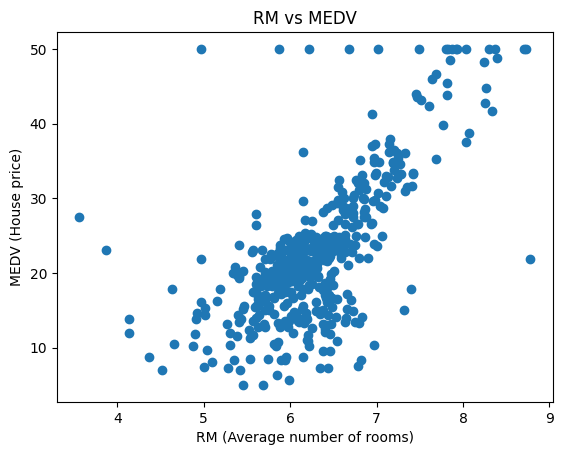

In [6]:
plt.scatter(df["RM"], df["MEDV"])
plt.xlabel("RM (Average number of rooms)")
plt.ylabel("MEDV (House price)")
plt.title("RM vs MEDV")
plt.show()

In [7]:
X = df[["RM"]].values
y = df["MEDV"].values

In [8]:
# ------------------------
# 1) Normalize X for stability
# ------------------------
X_mean, X_std = X.mean(), X.std()
Xn = (X - X_mean) / X_std
x = Xn.flatten()
m = len(x)

In [9]:
# ------------------------
# 2) Initialize parameters
# ------------------------
w = 0.0          # slope (ওজন)
b = 0.0          # intercept (বায়াস)
lr = 0.1         # learning rate
epochs = 1000    # কতবার আপডেট করব

y_true = y       # আসল দাম
losses = []      # প্রতি ধাপের loss রাখার জন্য

# ------------------------
# 3) Gradient Descent loop
# ------------------------
for i in range(epochs):
    y_pred = w * x + b                       # প্রেডিকশন

    error = y_pred - y_true
    loss = (error ** 2).mean()               # MSE loss
    losses.append(loss)

    dw = (2 / m) * (error * x).sum()         # w এর gradient
    db = (2 / m) * error.sum()               # b এর gradient

    w = w - lr * dw                          # w আপডেট
    b = b - lr * db                          # b আপডেট

    if i % 100 == 0:
        print(f"Epoch {i}: loss = {loss:.4f}, w = {w:.4f}, b = {b:.4f}")

print("Final w:", w, "b:", b)

Epoch 0: loss = 592.1469, w = 1.2778, b = 4.5066
Epoch 100: loss = 43.6006, w = 6.3890, b = 22.5328
Epoch 200: loss = 43.6006, w = 6.3890, b = 22.5328
Epoch 300: loss = 43.6006, w = 6.3890, b = 22.5328
Epoch 400: loss = 43.6006, w = 6.3890, b = 22.5328
Epoch 500: loss = 43.6006, w = 6.3890, b = 22.5328
Epoch 600: loss = 43.6006, w = 6.3890, b = 22.5328
Epoch 700: loss = 43.6006, w = 6.3890, b = 22.5328
Epoch 800: loss = 43.6006, w = 6.3890, b = 22.5328
Epoch 900: loss = 43.6006, w = 6.3890, b = 22.5328
Final w: 6.388975221817342 b: 22.532806324110666


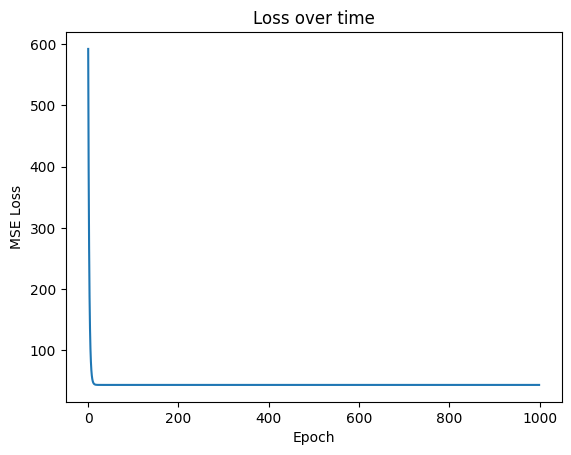

In [10]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Loss over time")
plt.show()

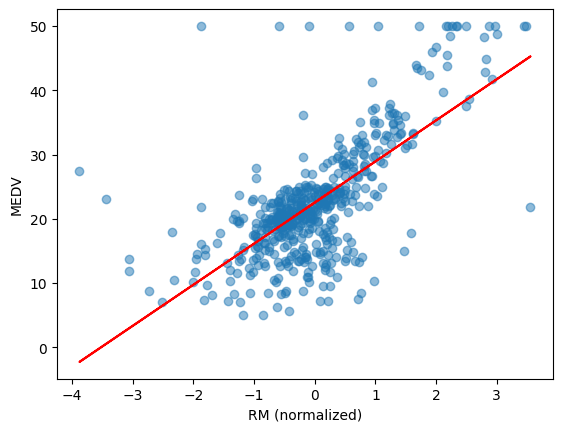

In [11]:
plt.scatter(x, y_true, alpha=0.5)
plt.plot(x, w * x + b, color="red")
plt.xlabel("RM (normalized)")
plt.ylabel("MEDV")
plt.show()

In [12]:
print("Final w:", w)
print("Final b:", b)

Final w: 6.388975221817342
Final b: 22.532806324110666


In [13]:
mae  = np.abs(y_true - y_pred).mean()
mse  = ((y_true - y_pred) ** 2).mean()
rmse = np.sqrt(mse)
r2   = 1 - ((y_true - y_pred) ** 2).sum() / ((y_true - y_true.mean()) ** 2).sum()

print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.2f}")

MAE  : 4.45
MSE  : 43.60
RMSE : 6.60
R²   : 0.48


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = w * x + b

mae  = mean_absolute_error(y_true, y_pred)
mse  = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_true, y_pred)

print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.2f}")

MAE  : 4.45
MSE  : 43.60
RMSE : 6.60
R²   : 0.48


In [16]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(Xn, y)          # Xn হলো normalize করা 2D X

print("Slope (w):", model.coef_[0])
print("Intercept (b):", model.intercept_)
print("R²:", model.score(Xn, y))

Slope (w): 6.388975221817343
Intercept (b): 22.532806324110677
R²: 0.48352545599133423


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred_test = model.predict(X_test)
print("Test R²:", r2_score(y_test, y_pred_test))

Test R²: 0.3707569232254778


In [18]:
X_all = df.drop("MEDV", axis=1)
y = df["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(
    X_all, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("MAE :", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²  :", r2_score(y_test, y_pred))

MAE : 3.189091965887837
RMSE: 4.928602182665332
R²  : 0.6687594935356326
